# Price forecasts across the horizon

Each day at 10:00 London time a forecast covers every half-hour from the issue to the end of the next local day: about 28 periods for the rest of today (**Block A**) and 48 for tomorrow (**Block B**), a lead time of 0 to about 38 hours. These figures show what a forecast looks like end to end, how accuracy and uncertainty change with lead time, and how the view of one day sharpens as it approaches.
Backtest issues 2025-10-01 to 2026-09-30, weekly recalibration, £/MWh, times in Europe/London.

In [1]:
import os, sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path[:0] = [str(ROOT / "src"), str(ROOT)]
warnings.filterwarnings("ignore")
%matplotlib inline

from v2g.forecast import plots

plots.apply_style()
data = plots.load_backtest()
print(plots.describe(data))

110,712 scored rows for 4 models over 365 daily issues (2025-10-01 to 2026-09-30, targets with a known actual price).


### One forecast, end to end

The issue whose `lear_x` error is closest to its median over the backtest, i.e. a typical day.

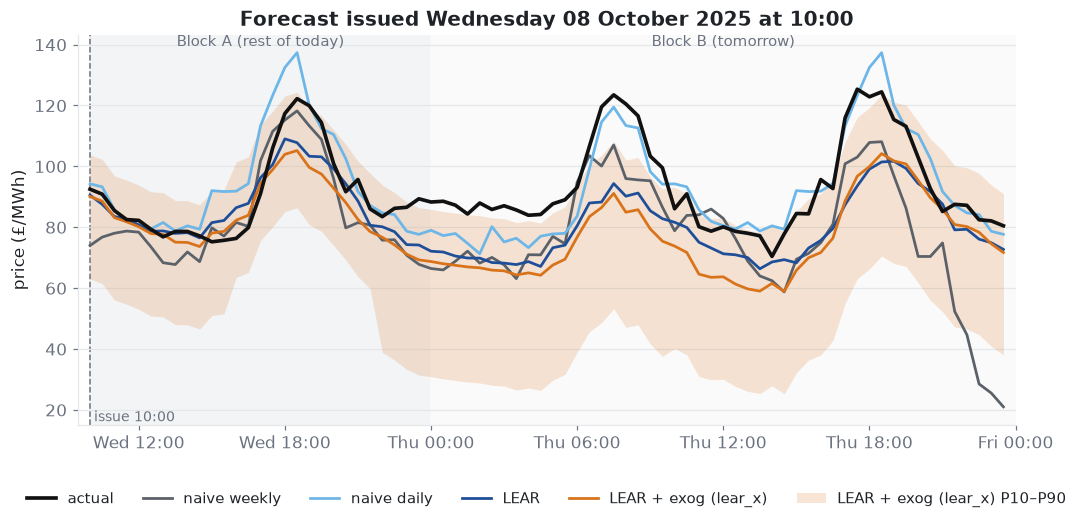

In [2]:
issue = plots.typical_issue(data)
fig = plots.plot_issue(data, issue)
plots.save(fig, "02_01_issue");

Issued Wednesday 8 October 2025: `lear_x`'s MAE is 14.0 £/MWh here against a backtest median of 14.1. It gets Block A nearly right (MAE 7.3) but under-calls both evening peaks and Thursday's midday level by about 16 £/MWh, so Block B's MAE is 18.0 and the P10–P90 band holds the actual on two-thirds of the periods.

### Four contrasting days

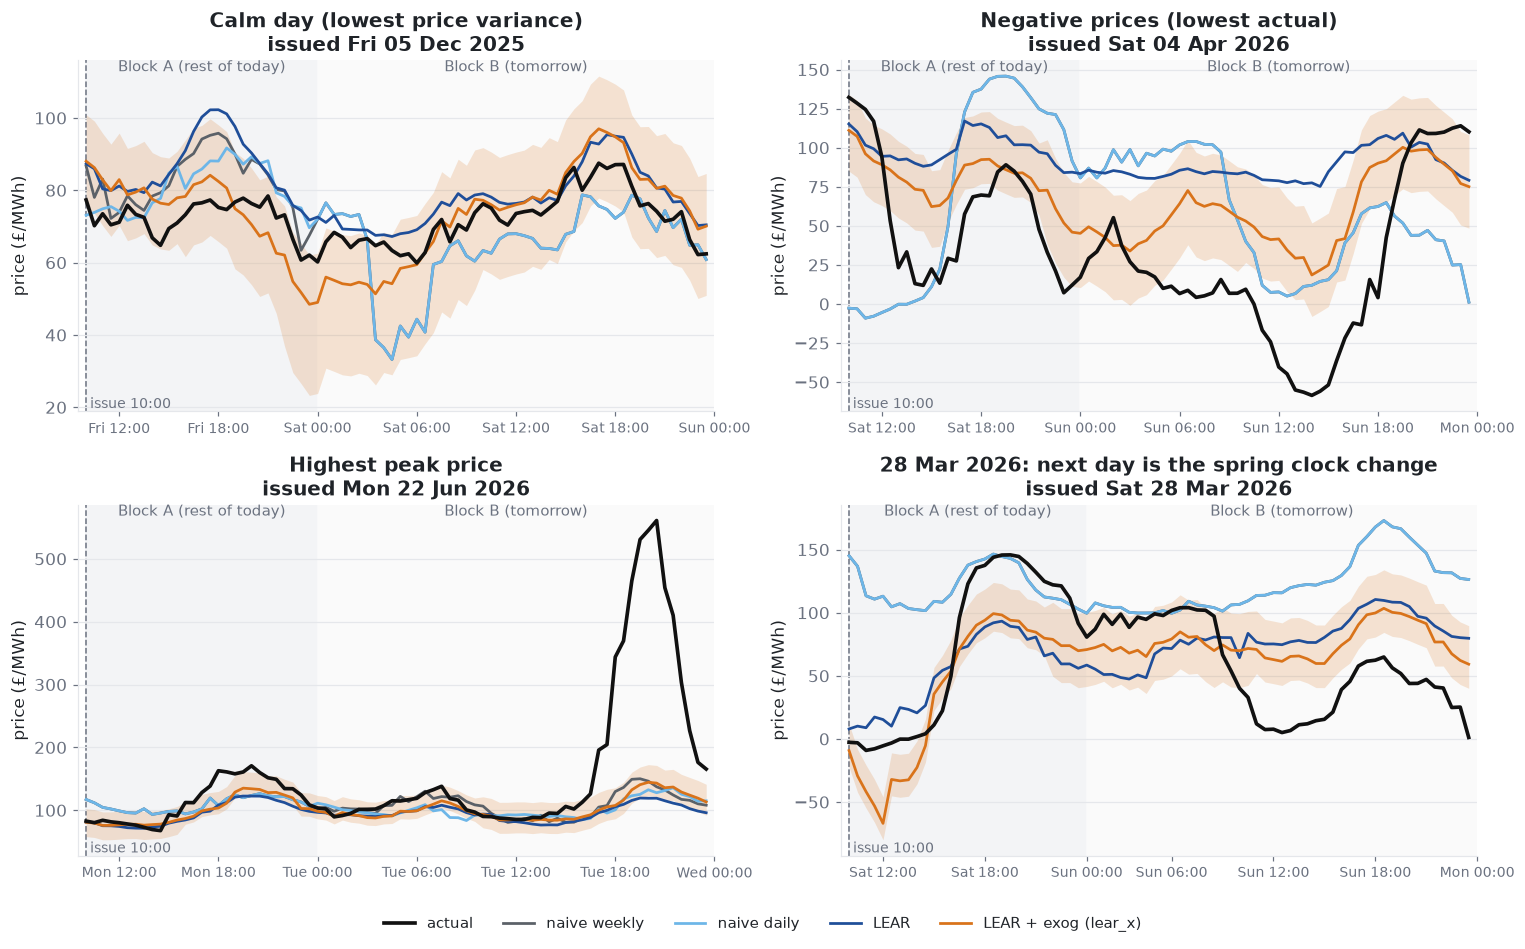

In [3]:
fig = plots.plot_issue_grid(data, plots.contrasting_issues(data))
plots.save(fig, "02_02_issue_grid");

On the calm day (5 Dec 2025, prices 60–87 £/MWh) every model is within 10 £/MWh and `lear_x` reaches 7.0. On the negative-price day (4 Apr 2026, minimum −59) `lear_x` is closest (MAE 39.7 against 63–65): it points down to about 30 £/MWh on Sunday afternoon where the actual averages −50, while LEAR never leaves 75–117 and the naive models sit at 137 on Saturday evening against an actual of 70. Nobody foresees the 561 £/MWh spike of 22 Jun 2026 (all models 54–59), and on 28 Mar 2026, whose next day has 74 periods, `lear_x` scores 35.6 against 42.9 for LEAR and 62.7 for the naive models.

### How accuracy decays with lead time

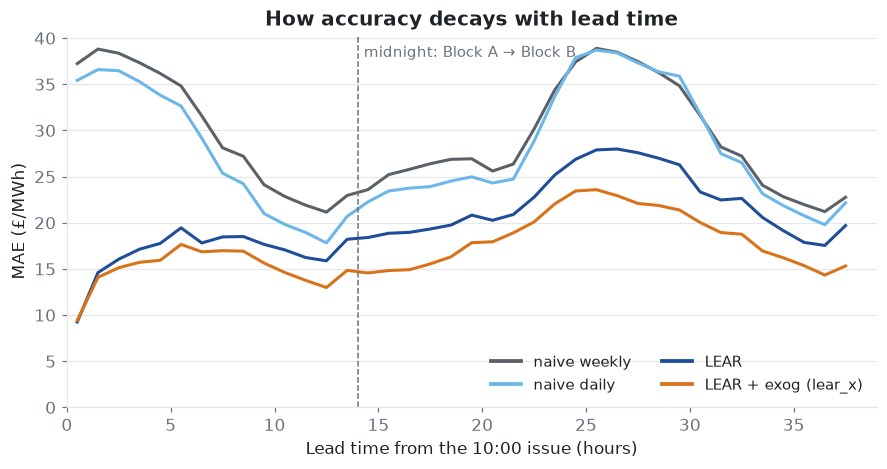

In [4]:
fig = plots.plot_mae_by_lead(data)
plots.save(fig, "02_03_mae_lead");

`lear_x` error grows from 9.4 £/MWh at lead 0 to 14.6 at midnight (14 h) and 20.0 at 30 h. The naive models are worst at the shortest leads (35–37 at lead 0) because they copy yesterday's price instead of using this morning's; their error only approaches the model-based ones around midnight.

### Uncertainty versus lead time (`lear_x`)

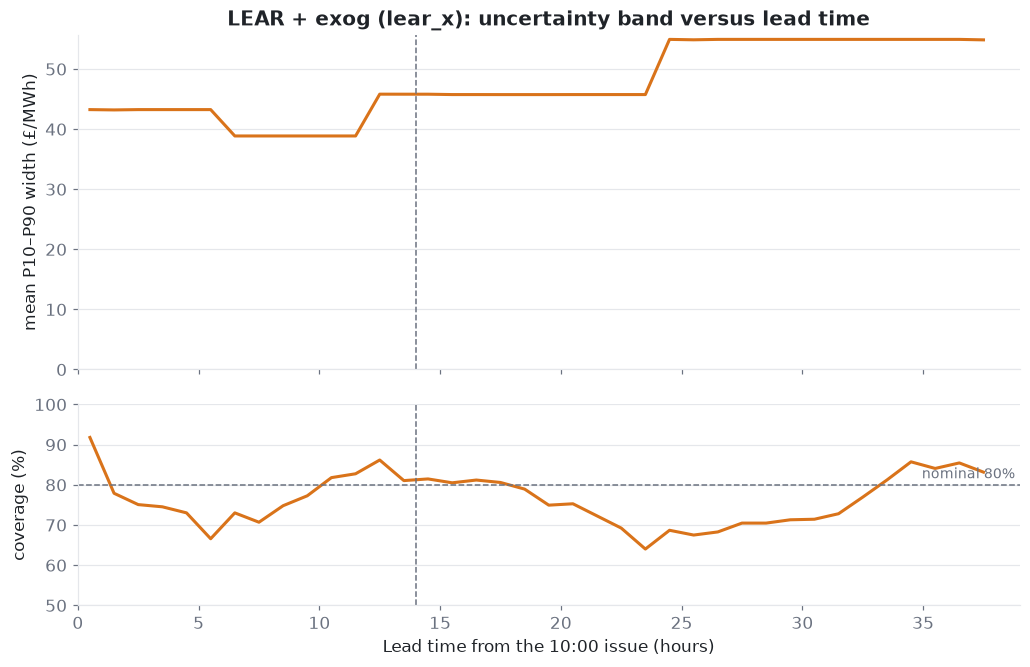

In [5]:
fig = plots.plot_width_by_lead(data)
plots.save(fig, "02_04_width_lead");

The P10–P90 band averages 48 £/MWh wide, growing from 39–43 in Block A to 55 at 24 h. Coverage is uneven across the horizon, 92% at lead 0 but 69–73% near 6 h and 24 h, because the quantiles are calibrated per lead bucket (0–6, 6–12, 12–24, 24–40 h) rather than per hour.

### Forecast against actual

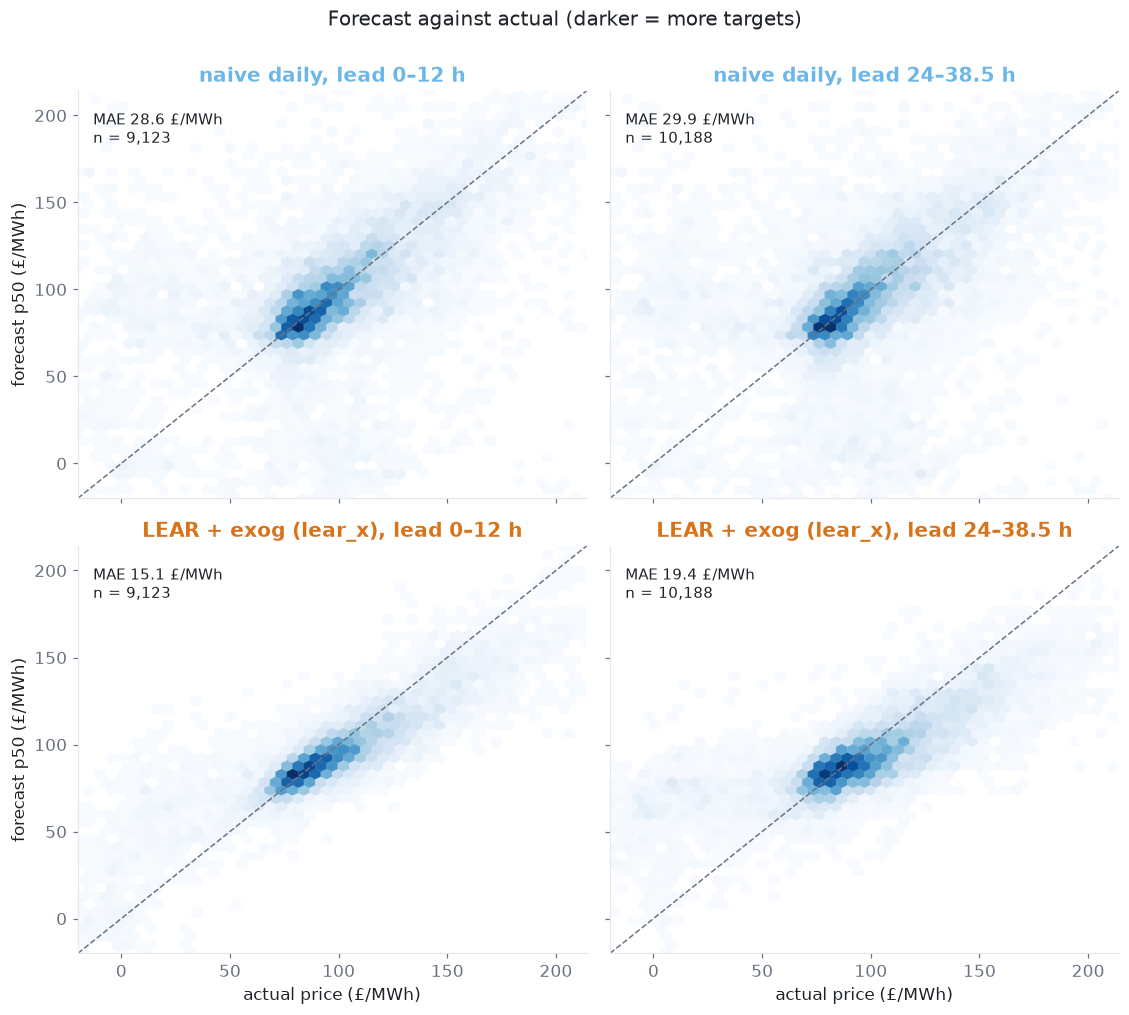

In [6]:
fig = plots.plot_pred_vs_actual(data)
plots.save(fig, "02_05_pred_vs_actual");

`lear_x` hugs the diagonal at 0–12 h (MAE 15.1 £/MWh) and loosens at 24–38 h (19.4), while naive daily is equally scattered at both horizons (28.6 and 29.9). Both under-forecast the highest prices: the top-right points sit below the line.

### Forecasts converging on the same day

The day after the typical issue, seen first from the issue the day before (lead 14–38 h) and then from the same-day issue (lead 0–14 h).

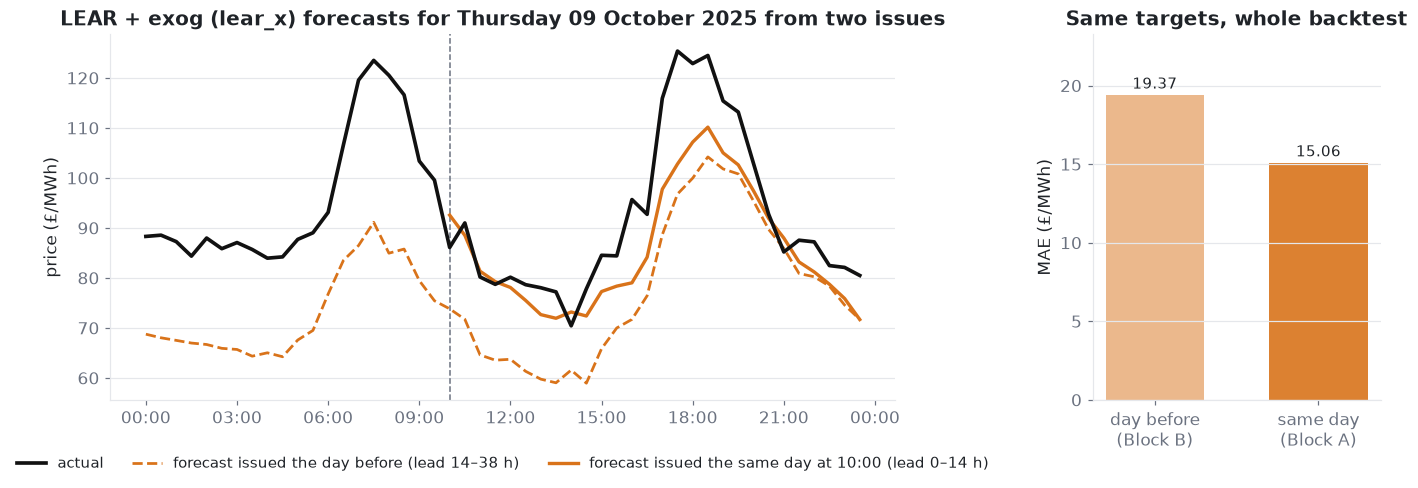

In [7]:
fig = plots.plot_convergence(data, plots.next_local_day(data, issue))
plots.save(fig, "02_06_convergence");

For Thursday 9 October 2025 the same-day issue halves the error of the day-before issue over the periods after 10:00 (7.3 vs 14.4 £/MWh). Across the whole backtest the same targets improve from 19.37 to 15.06 £/MWh (−22%) when forecast 24 hours later.

## Conclusions

- Accuracy decays smoothly with lead time: `lear_x` goes from 9.4 £/MWh at lead 0 to 14.6 at midnight and 20.0 at 30 h, so a plan built at 10:00 is most reliable for this evening and loosest for tomorrow evening.
- Re-forecasting helps: the same targets are 22% more accurate from the same-day issue than from the day before (15.06 vs 19.37), so the optimiser should re-solve each morning rather than fix tomorrow's plan a day early.
- Spikes and negative prices are where the risk sits: `lear_x` beats the alternatives on both, but no model anticipates a 561 £/MWh spike, and the upper band is too narrow.